## Install ConsiStory and compatible dependencies

In [1]:
%cd /content

!rm -rf consistory
!git clone https://github.com/NVlabs/consistory.git

%pip uninstall -y \
    diffusers \
    transformers \
    huggingface_hub \
    accelerate \
    tokenizers \
    datasets \
    peft

%pip install -q --no-cache-dir \
    diffusers==0.23.1 \
    transformers==4.48.3 \
    tokenizers==0.21.0 \
    huggingface-hub==0.25.2 \
    accelerate==0.30.0 \
    safetensors \
    scikit-image==0.25.2 \
    scipy \
    opencv-python-headless \
    matplotlib

%cd /content/consistory

/content
Cloning into 'consistory'...
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 18 (delta 1), reused 1 (delta 1), pack-reused 14 (from 1)
Receiving objects: 100% (18/18), 41.64 KiB | 10.41 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Found existing installation: diffusers 0.42.1
Uninstalling diffusers-0.42.1:
  Successfully uninstalled diffusers-0.42.1
Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1
Found existing installation: huggingface_hub 1.33.0
Uninstalling huggingface_hub-1.33.0:
  Successfully uninstalled huggingface_hub-1.33.0
Found existing installation: accelerate 1.15.0
Uninstalling accelerate-1.15.0:
  Successfully uninstalled accelerate-1.15.0
Found existing installation: tokenizers 0.23.3
Uninstalling tokenizers-0.23.3:
  Successfully uninstalled tokenizers-0.23.3
Found existing install

## restart the Colab session

Imports + PyTorch SDPA attention backend

This keeps the compatibility change we need

In [6]:
%cd /content/consistory

import sys
import gc
import json

from pathlib import Path

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.insert(0, "/content/consistory")

import consistory_utils
import attention_processor

import os
import glob
import time
import json

import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt



class TorchSDPAOps:
    """
    Replacement for xFormers memory-efficient attention using
    PyTorch scaled-dot-product attention.
    """

    @staticmethod
    def memory_efficient_attention(
        query,
        key,
        value,
        op=None,
        scale=None,
        **kwargs,
    ):
        return F.scaled_dot_product_attention(
            query,
            key,
            value,
            attn_mask=None,
            dropout_p=0.0,
            is_causal=False,
            scale=scale,
        )


class TorchXFormersFallback:
    ops = TorchSDPAOps()


# ConsiStory expects an xFormers-style attention interface.
xformers_fallback = TorchXFormersFallback()

consistory_utils.xformers = xformers_fallback
attention_processor.xformers = xformers_fallback


from consistory_run import (
    load_pipeline,
    run_anchor_generation,
    run_extra_generation,
)

print("✓ ConsiStory ready")

/content/consistory
✓ ConsiStory ready


### Load the ConsiStory SDXL pipeline

In [2]:
gc.collect()
torch.cuda.empty_cache()

story_pipeline = load_pipeline(0)

# Reduce SDXL VAE memory usage.
story_pipeline.enable_vae_slicing()
story_pipeline.enable_vae_tiling()

print("Pipeline loaded:", type(story_pipeline).__name__)
print("GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_token.py:90: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/10.3G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/479 [00:00<?, ?B/s]

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

... (11 outputs left out)

diffusion_pytorch_model.fp16.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

diffusion_pytorch_model.fp16.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Pipeline loaded: ConsistoryExtendAttnSDXLPipeline
GPU: NVIDIA L4


## Experiment configuration

In [3]:
CONCEPT_TOKEN = ["vampire"]

# Clean identity references used only to establish the cached
# ConsiStory subject representation.
ANCHOR_PROMPTS = [
    (
        "a western animation vampire, front-facing portrait, "
        "clean character design"
    ),
    (
        "a western animation vampire, three-quarter view portrait, "
        "clean character design"
    ),
]


# Actions corresponding to the storyboard sequence.
VAMPIRE_PROMPTS = [
    (
        "a western animation frame of a vampire obscured by jelly mist, "
        "the jelly vaporizes as the camera pans upward, "
        "blank background"
    ),
    (
        "a western animation frame of a vampire, "
        "the vampire's hands slowly enter the frame through jelly mist, "
        "close-up, blank background"
    ),
    (
        "a western animation frame of a vampire, "
        "the vampire's hands rapidly push vaporized jelly mist upward, "
        "close-up, blank background"
    ),
    (
        "a western animation frame of a vampire, "
        "camera pans upward to the vampire's face, "
        "close-up, blank background"
    ),
    (
        "a western animation frame of a vampire, "
        "the vampire inhales jelly mist from the right hand, "
        "close-up, blank background"
    ),
    (
        "a western animation frame of a vampire, "
        "the vampire inhales jelly mist from the left hand, "
        "close-up, blank background"
    ),
]


SEED = 42
NUM_STEPS = 50
MASK_DROPOUT = 0.5
SAME_LATENT = False

print(f"Configured {len(VAMPIRE_PROMPTS)} storyboard prompts")

Configured 6 storyboard prompts


In [7]:
PDF_PATH       = '/content/drive/MyDrive/cmpe261_project/storyboard/Evicted-Storyboard.pdf'
STORYBOARD_DIR = '/content/drive/MyDrive/cmpe261_project/pages'
PANEL_DIR      = '/content/drive/MyDrive/cmpe261_project/panels'
OUTPUT_DIR     = '/content/drive/MyDrive/cmpe261_project/outputs'
REF_DIR        = '/content/drive/MyDrive/cmpe261_project/char_refs'

In [8]:
seq_name = 'seq01'

panel_files = sorted(
    glob.glob(
        os.path.join(
            PANEL_DIR,
            f'{seq_name}_panel*.png'
        )
    )
)

In [9]:
from google.colab import drive

drive.mount('/content/drive')



# Same project paths used by the other baselines.
PDF_PATH = (
    '/content/drive/MyDrive/'
    'cmpe261_project/storyboard/'
    'Evicted-Storyboard.pdf'
)

STORYBOARD_DIR = (
    '/content/drive/MyDrive/'
    'cmpe261_project/pages'
)

PANEL_DIR = (
    '/content/drive/MyDrive/'
    'cmpe261_project/panels'
)

OUTPUT_DIR = (
    '/content/drive/MyDrive/'
    'cmpe261_project/outputs'
)

REF_DIR = (
    '/content/drive/MyDrive/'
    'cmpe261_project/char_refs'
)


for directory in (
    STORYBOARD_DIR,
    PANEL_DIR,
    OUTPUT_DIR,
    REF_DIR,
):
    os.makedirs(
        directory,
        exist_ok=True,
    )


print('PDF exists:', os.path.exists(PDF_PATH))
print('Panel directory:', PANEL_DIR)
print('Output directory:', OUTPUT_DIR)

Mounted at /content/drive
PDF exists: True
Panel directory: /content/drive/MyDrive/cmpe261_project/panels
Output directory: /content/drive/MyDrive/cmpe261_project/outputs


## ConsiStory config

In [10]:
CONFIG = {
    # ConsiStory uses SDXL rather than SD1.5.
    "base_model":
        "stabilityai/stable-diffusion-xl-base-1.0",

    # SDXL Canny ControlNet will be added next.
    "controlnet":
        "diffusers/controlnet-canny-sdxl-1.0",

    # SDXL-native resolution.
    "resolution": 1024,

    # ConsiStory needs 50 steps because its released
    # DIFT feature extraction expects timestep 261.
    "steps": 50,

    "guidance_scale": 7.5,

    "controlnet_conditioning_scale": 1.0,

    # Same seed as the other baselines.
    "seed": 42,

    # Same conditioning mode and thresholds.
    "cond_mode": "canny",
    "canny_low": 100,
    "canny_high": 200,

    # Keep the same suffix / negative prompt used
    # by the other baseline notebooks.
    "prompt_suffix":
        "clean colored animation frame, "
        "consistent character design",

    "negative_prompt":
        "blurry, low quality, deformed, "
        "extra limbs, text, watermark",

    # ConsiStory-specific settings.
    "mask_dropout": 0.5,
    "same_latent": False,
    "share_queries": True,
    "n_anchors": 2,
}

In [11]:
def load_rgb(path):
    return Image.open(path).convert('RGB')


def show(
    images,
    titles=None,
    cols=4,
    size=4,
):
    rows = (
        len(images) + cols - 1
    ) // cols

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(
            cols * size,
            rows * size,
        ),
    )

    axes = np.array(
        axes
    ).reshape(-1)

    for ax in axes:
        ax.axis('off')

    for i, image in enumerate(images):
        axes[i].imshow(image)

        if titles:
            axes[i].set_title(
                titles[i],
                fontsize=9,
            )

    plt.tight_layout()
    plt.show()


def make_condition(
    img,
    mode='canny',
    size=1024,
    low=100,
    high=200,
):
    """
    Same conditioning helper as the existing
    ControlNet / IP-Adapter notebooks.

    Only the default resolution changes because
    ConsiStory uses SDXL.
    """

    img = img.resize(
        (size, size)
    )

    gray = np.array(
        img.convert('L')
    )

    if mode == 'canny':
        cond = cv2.Canny(
            gray,
            low,
            high,
        )

    elif mode == 'invert':
        cond = 255 - gray

    else:
        raise ValueError(mode)

    return Image.fromarray(
        cond
    ).convert('RGB')

### load the exact same sequence and prompts

In [12]:
seq_name = 'seq01'

panel_files = sorted(
    glob.glob(
        os.path.join(
            PANEL_DIR,
            f'{seq_name}_panel*.png'
        )
    )
)

CHAR = "a vampire"
SETTING = "blank background"

actions = [
    "jelly vaporizes as camera pans up",
    "vampire hands slowly come into screen, close-up",
    "hands rapidly push vaporized blood upwards, close-up",
    "camera pans upto vampire's face, close-up",
    "vampire inhales jelly mist from right hand, close-up",
    "vampire inhales jelly mist from left hand, close-up",
]

prompts = [
    f"{CHAR}, {action}, {SETTING}"
    for action in actions
][
    :len(panel_files)
]


print(
    f"Found {len(panel_files)} panels"
)

for i, (
    panel_file,
    prompt,
) in enumerate(
    zip(
        panel_files,
        prompts,
    ),
    1,
):
    print(
        f"{i}: "
        f"{os.path.basename(panel_file)} "
        f"-> {prompt}"
    )

Found 6 panels
1: seq01_panel001.png -> a vampire, jelly vaporizes as camera pans up, blank background
2: seq01_panel002.png -> a vampire, vampire hands slowly come into screen, close-up, blank background
3: seq01_panel003.png -> a vampire, hands rapidly push vaporized blood upwards, close-up, blank background
4: seq01_panel004.png -> a vampire, camera pans upto vampire's face, close-up, blank background
5: seq01_panel005.png -> a vampire, vampire inhales jelly mist from right hand, close-up, blank background
6: seq01_panel006.png -> a vampire, vampire inhales jelly mist from left hand, close-up, blank background


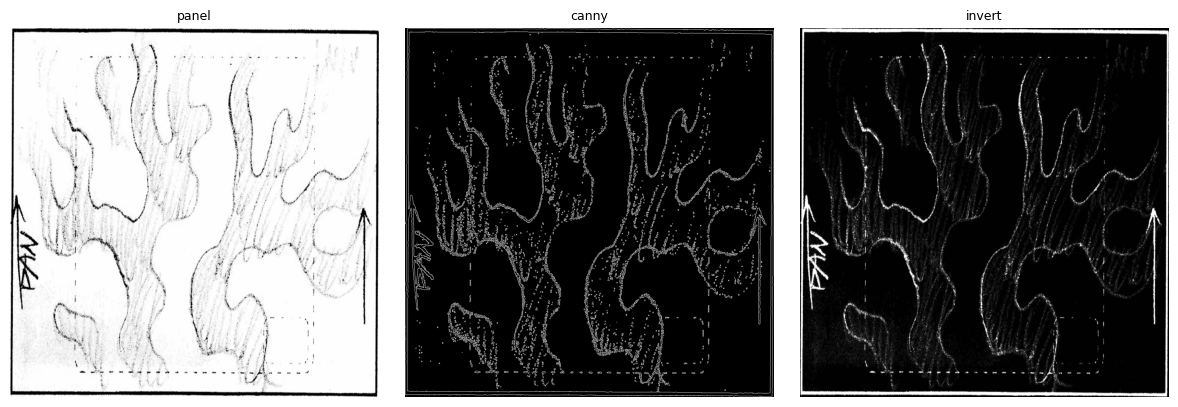

In [13]:
if panel_files:

    test = load_rgb(
        panel_files[0]
    )

    show(
        [
            test.resize(
                (
                    CONFIG["resolution"],
                    CONFIG["resolution"],
                )
            ),

            make_condition(
                test,
                'canny',
                CONFIG["resolution"],
                CONFIG["canny_low"],
                CONFIG["canny_high"],
            ),

            make_condition(
                test,
                'invert',
                CONFIG["resolution"],
                CONFIG["canny_low"],
                CONFIG["canny_high"],
            ),
        ],

        titles=[
            'panel',
            'canny',
            'invert',
        ],

        cols=3,
    )

## Generate the reusable ConsiStory anchors

insert the ConsiStory anchor setup before loading ControlNet. This avoids wasting L4 VRAM while the anchors are being built.

In [14]:
from consistory_run import (
    run_anchor_generation,
    run_extra_generation,
)

CONCEPT_TOKEN = ["vampire"]

ANCHOR_PROMPTS = [
    "a western animation vampire, front-facing portrait, clean character design",
    "a western animation vampire, three-quarter view portrait, clean character design",
]

story_pipeline.unet.latent_store.reset()

gc.collect()
torch.cuda.empty_cache()

(
    anchor_images,
    anchor_grid,
    anchor_cache_first_stage,
    anchor_cache_second_stage,
) = run_anchor_generation(
    story_pipeline=story_pipeline,
    prompts=ANCHOR_PROMPTS,
    concept_token=CONCEPT_TOKEN,

    seed=CONFIG["seed"],
    n_steps=CONFIG["steps"],
    mask_dropout=CONFIG["mask_dropout"],

    same_latent=CONFIG["same_latent"],
    share_queries=CONFIG["share_queries"],

    perform_sdsa=True,
    perform_injection=True,

    # Keep large caches in system RAM.
    cache_cpu_offloading=True,
)

print("✓ ConsiStory identity anchors generated")

[(1, 50)]


  0%|          | 0/50 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/torch_utils.py:106: UserWarning: ComplexHalf support is experimental and many operators don't support it yet. (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/EmptyTensor.cpp:54.)
  x_freq = fftn(x, dim=(-2, -1))


  0%|          | 0/50 [00:00<?, ?it/s]

✓ ConsiStory identity anchors generated


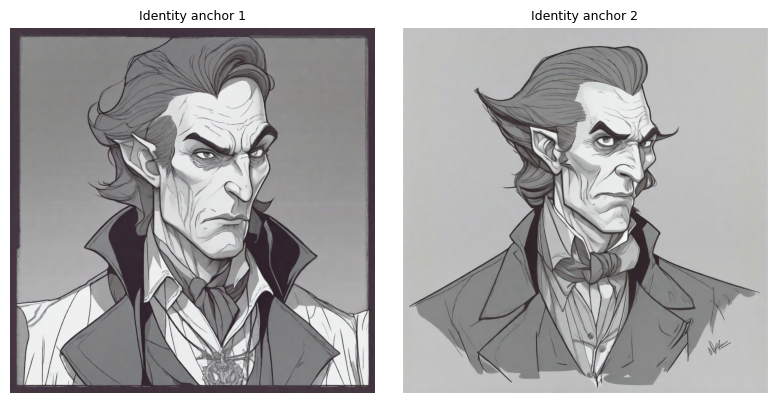

In [15]:
show(
    anchor_images,
    titles=[
        "Identity anchor 1",
        "Identity anchor 2",
    ],
    cols=2,
)

## Load SDXL Canny ControlNet

Use the SDXL Canny checkpoint corresponding to the SDXL backbone. Hugging Face's SDXL ControlNet pipeline uses diffusers/controlnet-canny-sdxl-1.0; ControlNet produces down-block and mid-block residuals that are injected into the UNet.

In [16]:
from diffusers import ControlNetModel

gc.collect()
torch.cuda.empty_cache()

controlnet = ControlNetModel.from_pretrained(
    CONFIG["controlnet"],
    torch_dtype=torch.float16,
).to("cuda")

controlnet.eval()

print(
    "✓ ControlNet loaded:",
    CONFIG["controlnet"],
)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/outputs.py:63: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

✓ ControlNet loaded: diffusers/controlnet-canny-sdxl-1.0


### Control-image preprocessing

In [17]:
from diffusers.image_processor import VaeImageProcessor

control_image_processor = VaeImageProcessor(
    vae_scale_factor=story_pipeline.vae_scale_factor,
    do_convert_rgb=True,
    do_normalize=False,
)


def prepare_control_image(condition):
    """
    Convert a PIL Canny condition into the tensor format
    expected by SDXL ControlNet.
    """
    tensor = control_image_processor.preprocess(
        condition,
        height=CONFIG["resolution"],
        width=CONFIG["resolution"],
    )

    return tensor.to(
        device="cuda",
        dtype=torch.float16,
    )

### transparent ConsiStory + ControlNet wrapper

Our wrapper only exposed a few attributes like config and latent_store, so the underlying ConsiStory UNet's add_embedding became hidden. The wrapper delegate any unknown attribute to the real ConsiStory UNet.

In [18]:
import torch.nn as nn


class ConsistoryControlNetUNet(nn.Module):
    """
    Transparent wrapper around the ConsiStory SDXL UNet.

    Unknown attributes are delegated to the original ConsiStory UNet,
    so the SDXL pipeline can still access things such as:

        add_embedding
        config
        dtype
        attn_processors
        encoder_hid_proj
        etc.

    During forward():
      1. ControlNet produces structural residuals.
      2. Those residuals are passed into the ConsiStory UNet.
    """

    def __init__(
        self,
        unet,
        controlnet,
        conditioning_scale=1.0,
    ):
        super().__init__()

        self.base_unet = unet
        self.controlnet = controlnet

        self.conditioning_scale = (
            conditioning_scale
        )

        self.control_image = None


    def __getattr__(self, name):
        """
        First let nn.Module resolve normal modules,
        parameters, buffers, and wrapper attributes.

        If the attribute does not exist on the wrapper,
        delegate it to the wrapped ConsiStory UNet.
        """
        try:
            return super().__getattr__(name)

        except AttributeError:
            base_unet = super().__getattr__(
                "base_unet"
            )

            return getattr(
                base_unet,
                name,
            )


    def set_control_image(
        self,
        control_image,
    ):
        self.control_image = control_image


    def clear_control_image(self):
        self.control_image = None


    def forward(
        self,
        sample,
        timestep,
        encoder_hidden_states,
        timestep_cond=None,
        cross_attention_kwargs=None,
        added_cond_kwargs=None,
        return_dict=True,
        **kwargs,
    ):

        # ------------------------------------------
        # No ControlNet condition:
        # behave exactly like normal ConsiStory.
        # ------------------------------------------
        if self.control_image is None:

            return self.base_unet(
                sample,
                timestep,

                encoder_hidden_states=(
                    encoder_hidden_states
                ),

                timestep_cond=timestep_cond,

                cross_attention_kwargs=(
                    cross_attention_kwargs
                ),

                added_cond_kwargs=(
                    added_cond_kwargs
                ),

                return_dict=return_dict,

                **kwargs,
            )


        # ------------------------------------------
        # Match ControlNet condition batch size
        # to the current UNet latent batch.
        # ------------------------------------------
        control_cond = self.control_image

        if (
            control_cond.shape[0]
            != sample.shape[0]
        ):
            assert (
                sample.shape[0]
                % control_cond.shape[0]
                == 0
            ), (
                "Control image batch cannot "
                "be matched to latent batch"
            )

            repeats = (
                sample.shape[0]
                // control_cond.shape[0]
            )

            control_cond = (
                control_cond.repeat(
                    repeats,
                    1,
                    1,
                    1,
                )
            )


        control_cond = control_cond.to(
            device=sample.device,
            dtype=sample.dtype,
        )


        # ------------------------------------------
        # ControlNet structural conditioning.
        # ------------------------------------------
        (
            down_block_res_samples,
            mid_block_res_sample,
        ) = self.controlnet(
            sample,
            timestep,

            encoder_hidden_states=(
                encoder_hidden_states
            ),

            controlnet_cond=control_cond,

            conditioning_scale=(
                self.conditioning_scale
            ),

            added_cond_kwargs=(
                added_cond_kwargs
            ),

            return_dict=False,
        )


        # ------------------------------------------
        # Original ConsiStory UNet receives the
        # structural ControlNet residuals.
        # ------------------------------------------
        return self.base_unet(
            sample,
            timestep,

            encoder_hidden_states=(
                encoder_hidden_states
            ),

            timestep_cond=timestep_cond,

            cross_attention_kwargs=(
                cross_attention_kwargs
            ),

            added_cond_kwargs=(
                added_cond_kwargs
            ),

            down_block_additional_residuals=(
                down_block_res_samples
            ),

            mid_block_additional_residual=(
                mid_block_res_sample
            ),

            return_dict=return_dict,

            **kwargs,
        )

### Attach ControlNet without replacing the ConsiStory logic

In [19]:
original_consistory_unet = story_pipeline.unet

consistory_controlnet_unet = (
    ConsistoryControlNetUNet(
        unet=original_consistory_unet,
        controlnet=controlnet,
        conditioning_scale=(
            CONFIG[
                "controlnet_conditioning_scale"
            ]
        ),
    )
)

story_pipeline.unet = (
    consistory_controlnet_unet
)

print(
    "✓ ControlNet attached to "
    "ConsiStory UNet"
)

✓ ControlNet attached to ConsiStory UNet


This avoids creating a completely separate StableDiffusionXLControlNetPipeline, which would lose the special ConsiStory attention/caching behavior. ConsiStory's own pipeline modifies the UNet attention processors and performs its extra query-sharing/injection passes, so we want to preserve that machinery.

### Do test run un panel 4

Panel: seq01_panel004.png
Prompt: a vampire, camera pans upto vampire's face, close-up, blank background, clean colored animation frame, consistent character design


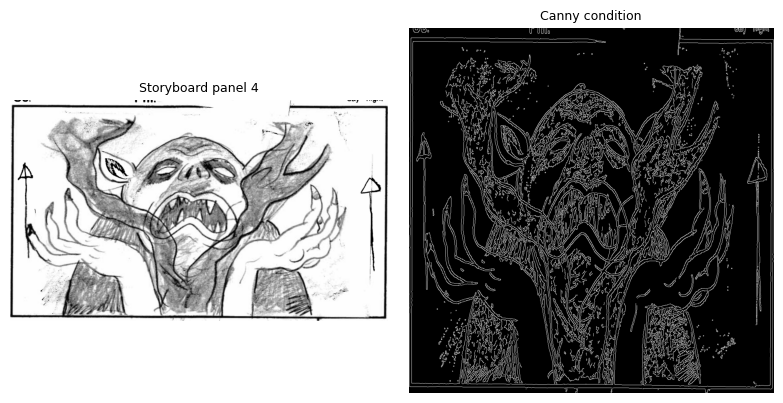

In [20]:
TEST_PANEL_INDEX = 3  # zero-based -> storyboard panel 4

test_panel_path = panel_files[TEST_PANEL_INDEX]

test_storyboard = load_rgb(
    test_panel_path
)

test_condition = make_condition(
    test_storyboard,
    mode=CONFIG["cond_mode"],
    size=CONFIG["resolution"],
    low=CONFIG["canny_low"],
    high=CONFIG["canny_high"],
)

# Keep the exact same base prompt used by the other baselines,
# then append the shared suffix.
test_prompt = (
    f"{prompts[TEST_PANEL_INDEX]}, "
    f"{CONFIG['prompt_suffix']}"
)

print("Panel:", os.path.basename(test_panel_path))
print("Prompt:", test_prompt)

show(
    [
        test_storyboard,
        test_condition,
    ],
    titles=[
        "Storyboard panel 4",
        "Canny condition",
    ],
    cols=2,
)

### Convert the Canny map to ControlNet input

In [21]:
test_control_tensor = prepare_control_image(
    test_condition
)

print("Control tensor shape:", test_control_tensor.shape)
print("dtype:", test_control_tensor.dtype)
print("device:", test_control_tensor.device)

Control tensor shape: torch.Size([1, 3, 1024, 1024])
dtype: torch.float16
device: cuda:0


### Attach the panel condition

In [22]:
story_pipeline.unet.set_control_image(
    test_control_tensor
)

story_pipeline.unet.conditioning_scale = (
    CONFIG["controlnet_conditioning_scale"]
)

print("✓ Panel 4 ControlNet condition attached")

✓ Panel 4 ControlNet condition attached


panel 4 storyboard

↓

Canny

↓

SDXL ControlNet

↓ residuals

ConsiStory UNet

↑

cached identity anchors

### Run cached ConsiStory + ControlNet on panel 4

In [23]:
story_pipeline.unet.latent_store.reset()

gc.collect()
torch.cuda.empty_cache()

test_images, test_grid = run_extra_generation(
    story_pipeline=story_pipeline,

    prompts=[
        test_prompt
    ],

    concept_token=CONCEPT_TOKEN,

    anchor_cache_first_stage=(
        anchor_cache_first_stage
    ),

    anchor_cache_second_stage=(
        anchor_cache_second_stage
    ),

    seed=CONFIG["seed"],
    n_steps=CONFIG["steps"],

    mask_dropout=CONFIG["mask_dropout"],

    same_latent=CONFIG["same_latent"],
    share_queries=CONFIG["share_queries"],

    perform_sdsa=True,
    perform_injection=True,

    cache_cpu_offloading=True,
)

print(
    "✓ Panel 4 ControlNet + "
    "ConsiStory generation completed"
)

[(1, 50)]


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

✓ Panel 4 ControlNet + ConsiStory generation completed


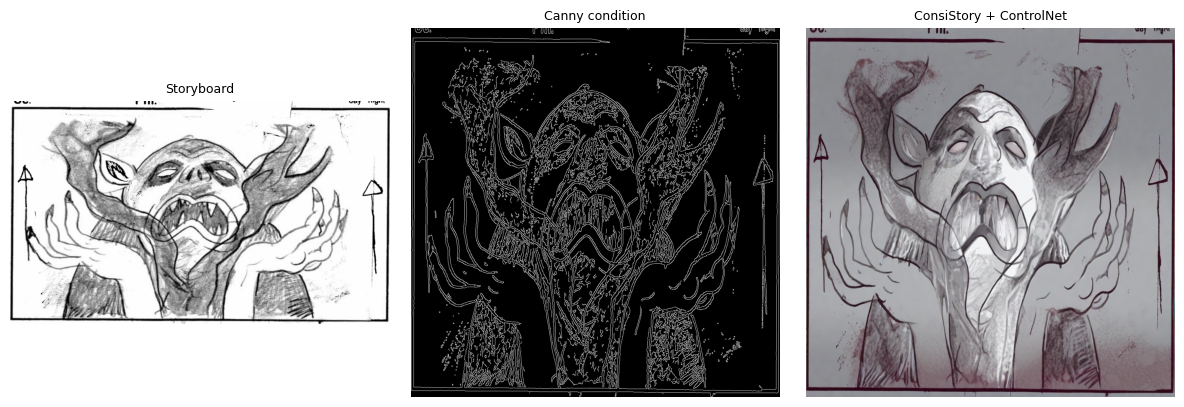

In [24]:
test_output = test_images[0]

show(
    [
        test_storyboard,
        test_condition,
        test_output,
    ],
    titles=[
        "Storyboard",
        "Canny condition",
        "ConsiStory + ControlNet",
    ],
    cols=3,
)

### Controlled cached ConsiStory generation helper

In [25]:
import consistory_run as cr


def run_extra_generation_controlled(
    story_pipeline,
    prompts,
    concept_token,
    anchor_cache_first_stage,
    anchor_cache_second_stage,
    seed=42,
    n_steps=50,
    mask_dropout=0.5,
    same_latent=False,
    share_queries=True,
    perform_sdsa=True,
    perform_injection=True,
    cache_cpu_offloading=True,
    guidance_scale=7.5,
    negative_prompt=None,
):
    """
    Cached ConsiStory generation following the official
    run_extra_generation() logic, while additionally exposing
    shared benchmark parameters such as CFG and negative prompt.
    """

    device = story_pipeline.device
    tokenizer = story_pipeline.tokenizer
    float_type = story_pipeline.dtype
    unet = story_pipeline.unet

    batch_size = len(prompts)

    # ------------------------------------------
    # Locate the subject token in each prompt.
    # ------------------------------------------
    token_indices = cr.create_token_indices(
        prompts,
        batch_size,
        concept_token,
        tokenizer,
    )

    attention_store_kwargs = {
        "token_indices": token_indices,
        "mask_dropout": mask_dropout,
    }

    extended_attn_base = {
        "extend_kv_unet_parts": ["up"],
    }

    query_store_kwargs = {
        "t_range": [
            0,
            n_steps // 10,
        ],
        "strength_start": 0.9,
        "strength_end": 0.81836735,
    }

    # Official cached mode reserves two slots for
    # the anchor representations.
    extra_batch_size = batch_size + 2

    if isinstance(seed, list):
        seed = [
            seed[0],
            seed[0],
            *seed,
        ]

    latents, generator = cr.create_latents(
        story_pipeline,
        seed,
        extra_batch_size,
        same_latent,
        device,
        float_type,
    )

    # Remove the two anchor latent slots.
    latents = latents[2:]

    anchor_cache_first_stage.set_mode_inject()
    anchor_cache_second_stage.set_mode_inject()

    # ------------------------------------------
    # Pass 1: Subject-Driven Shared Attention.
    # ------------------------------------------
    if cache_cpu_offloading:
        anchor_cache_first_stage.to_device(
            device
        )

    if perform_sdsa:
        extended_attn_kwargs = {
            **extended_attn_base,
            "t_range": [
                (1, n_steps)
            ],
        }
    else:
        extended_attn_kwargs = {
            **extended_attn_base,
            "t_range": [],
        }

    out = story_pipeline(
        prompt=prompts,

        negative_prompt=negative_prompt,
        guidance_scale=guidance_scale,

        generator=generator,
        latents=latents,

        attention_store_kwargs=(
            attention_store_kwargs
        ),

        extended_attn_kwargs=(
            extended_attn_kwargs
        ),

        share_queries=share_queries,

        query_store_kwargs=(
            query_store_kwargs
        ),

        anchors_cache=(
            anchor_cache_first_stage
        ),

        num_inference_steps=n_steps,
    )

    # ------------------------------------------
    # Extract target DIFT features + masks.
    # ------------------------------------------
    last_masks = (
        story_pipeline
        .attention_store
        .last_mask
    )

    dift_features = (
        unet
        .latent_store
        .dift_features["261_0"]
        [batch_size:]
    )

    dift_features = torch.stack(
        [
            cr.gaussian_smooth(
                x,
                kernel_size=3,
                sigma=1,
            )
            for x in dift_features
        ],
        dim=0,
    )

    anchor_dift_features = (
        anchor_cache_first_stage
        .dift_cache
    )

    anchor_last_masks = (
        anchor_cache_first_stage
        .anchors_last_mask
    )

    # Establish correspondence between the
    # generated target and the identity anchors.
    nn_map, nn_distances = (
        cr.anchor_nn_map(
            dift_features,
            anchor_dift_features,
            last_masks,
            anchor_last_masks,
            cr.LATENT_RESOLUTIONS,
            device,
        )
    )

    if cache_cpu_offloading:
        anchor_cache_first_stage.to_device(
            torch.device("cpu")
        )

    gc.collect()
    torch.cuda.empty_cache()

    # ------------------------------------------
    # Pass 2: Correspondence-based injection.
    # ------------------------------------------
    if perform_injection:

        if cache_cpu_offloading:
            anchor_cache_second_stage.to_device(
                device
            )

        feature_injector = cr.FeatureInjector(
            nn_map,
            nn_distances,
            last_masks,

            inject_range_alpha=[
                (
                    n_steps // 10,
                    n_steps // 3,
                    0.8,
                )
            ],

            swap_strategy="min",

            inject_unet_parts=[
                "up",
                "down",
            ],

            dist_thr="dynamic",
        )

        out = story_pipeline(
            prompt=prompts,

            negative_prompt=negative_prompt,
            guidance_scale=guidance_scale,

            generator=generator,
            latents=latents,

            attention_store_kwargs=(
                attention_store_kwargs
            ),

            extended_attn_kwargs=(
                extended_attn_kwargs
            ),

            share_queries=share_queries,

            query_store_kwargs=(
                query_store_kwargs
            ),

            feature_injector=(
                feature_injector
            ),

            anchors_cache=(
                anchor_cache_second_stage
            ),

            num_inference_steps=n_steps,
        )

        if cache_cpu_offloading:
            anchor_cache_second_stage.to_device(
                torch.device("cpu")
            )

    gc.collect()
    torch.cuda.empty_cache()

    return out.images

In [26]:
def run_sequence_consistory(
    seq_name,
    panel_files,
    prompts,
    anchor_cache_first_stage,
    anchor_cache_second_stage,
    method="controlnet_consistory",
    cfg=CONFIG,
):
    """
    Generate a storyboard sequence using:

        SDXL
        + Canny ControlNet
        + ConsiStory cached identity consistency

    The overall runner intentionally mirrors the existing
    ControlNet / IP-Adapter notebook structure.
    """

    assert len(panel_files) == len(prompts), \
        "need one prompt per panel"

    out_dir = os.path.join(
        OUTPUT_DIR,
        method,
        seq_name,
    )

    os.makedirs(
        out_dir,
        exist_ok=True,
    )

    results = []

    for i, (
        panel_file,
        prompt,
    ) in enumerate(
        zip(
            panel_files,
            prompts,
        ),
        1,
    ):

        print(
            f"\n{'=' * 60}\n"
            f"Generating panel {i}/"
            f"{len(panel_files)}\n"
            f"{'=' * 60}"
        )

        # --------------------------------------
        # Same storyboard structural extraction
        # used by the other baselines.
        # --------------------------------------
        cond = make_condition(
            load_rgb(panel_file),

            cfg["cond_mode"],
            cfg["resolution"],

            cfg["canny_low"],
            cfg["canny_high"],
        )

        control_tensor = (
            prepare_control_image(
                cond
            )
        )

        # Attach this storyboard panel to
        # ControlNet for both ConsiStory passes.
        story_pipeline.unet.set_control_image(
            control_tensor
        )

        story_pipeline.unet.conditioning_scale = (
            cfg[
                "controlnet_conditioning_scale"
            ]
        )

        # Avoid retaining DIFT features from
        # the preceding storyboard panel.
        story_pipeline.unet.latent_store.reset()

        gc.collect()
        torch.cuda.empty_cache()

        # Same shared text-prompt convention.
        full_prompt = (
            f"{prompt}, "
            f"{cfg['prompt_suffix']}"
        )

        try:
            images = (
                run_extra_generation_controlled(
                    story_pipeline=story_pipeline,

                    prompts=[
                        full_prompt
                    ],

                    concept_token=(
                        CONCEPT_TOKEN
                    ),

                    anchor_cache_first_stage=(
                        anchor_cache_first_stage
                    ),

                    anchor_cache_second_stage=(
                        anchor_cache_second_stage
                    ),

                    seed=cfg["seed"],
                    n_steps=cfg["steps"],

                    mask_dropout=(
                        cfg["mask_dropout"]
                    ),

                    same_latent=(
                        cfg["same_latent"]
                    ),

                    share_queries=(
                        cfg["share_queries"]
                    ),

                    perform_sdsa=True,
                    perform_injection=True,

                    cache_cpu_offloading=True,

                    guidance_scale=(
                        cfg["guidance_scale"]
                    ),

                    negative_prompt=(
                        cfg["negative_prompt"]
                    ),
                )
            )

            image = images[0]

            # ----------------------------------
            # Same naming convention as the
            # other baseline runners.
            # ----------------------------------
            image.save(
                os.path.join(
                    out_dir,
                    f"panel{i:02d}.png",
                )
            )

            cond.save(
                os.path.join(
                    out_dir,
                    f"panel{i:02d}_cond.png",
                )
            )

            results.append(
                image
            )

            print(
                f"✓ Panel {i} saved"
            )

        finally:
            # Remove the panel-specific
            # ControlNet condition.
            story_pipeline.unet.clear_control_image()

            del control_tensor

            gc.collect()
            torch.cuda.empty_cache()


    # ------------------------------------------
    # Reproducibility record.
    # ------------------------------------------
    record = {
        "method": method,

        "sequence": seq_name,

        "panel_files":
            panel_files,

        "prompts":
            prompts,

        "config":
            cfg,

        "consistory": {
            "concept_token":
                CONCEPT_TOKEN,

            "anchor_prompts":
                ANCHOR_PROMPTS,

            "perform_sdsa":
                True,

            "perform_injection":
                True,

            "cache_cpu_offloading":
                True,

            "attention_backend":
                "torch_sdpa",
        },

        "timestamp":
            time.strftime(
                "%Y-%m-%d %H:%M:%S"
            ),

        "torch":
            torch.__version__,
    }

    with open(
        os.path.join(
            out_dir,
            "run_config.json",
        ),
        "w",
    ) as f:

        json.dump(
            record,
            f,
            indent=2,
        )


    return results

### Run the final six-panel sequence

In [27]:
consistory_frames = run_sequence_consistory(
    seq_name=seq_name,

    panel_files=panel_files,

    prompts=prompts,

    anchor_cache_first_stage=(
        anchor_cache_first_stage
    ),

    anchor_cache_second_stage=(
        anchor_cache_second_stage
    ),
)


Generating panel 1/6


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

✓ Panel 1 saved

Generating panel 2/6


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

... (9 outputs left out)

✓ Panel 5 saved

Generating panel 6/6


  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

✓ Panel 6 saved


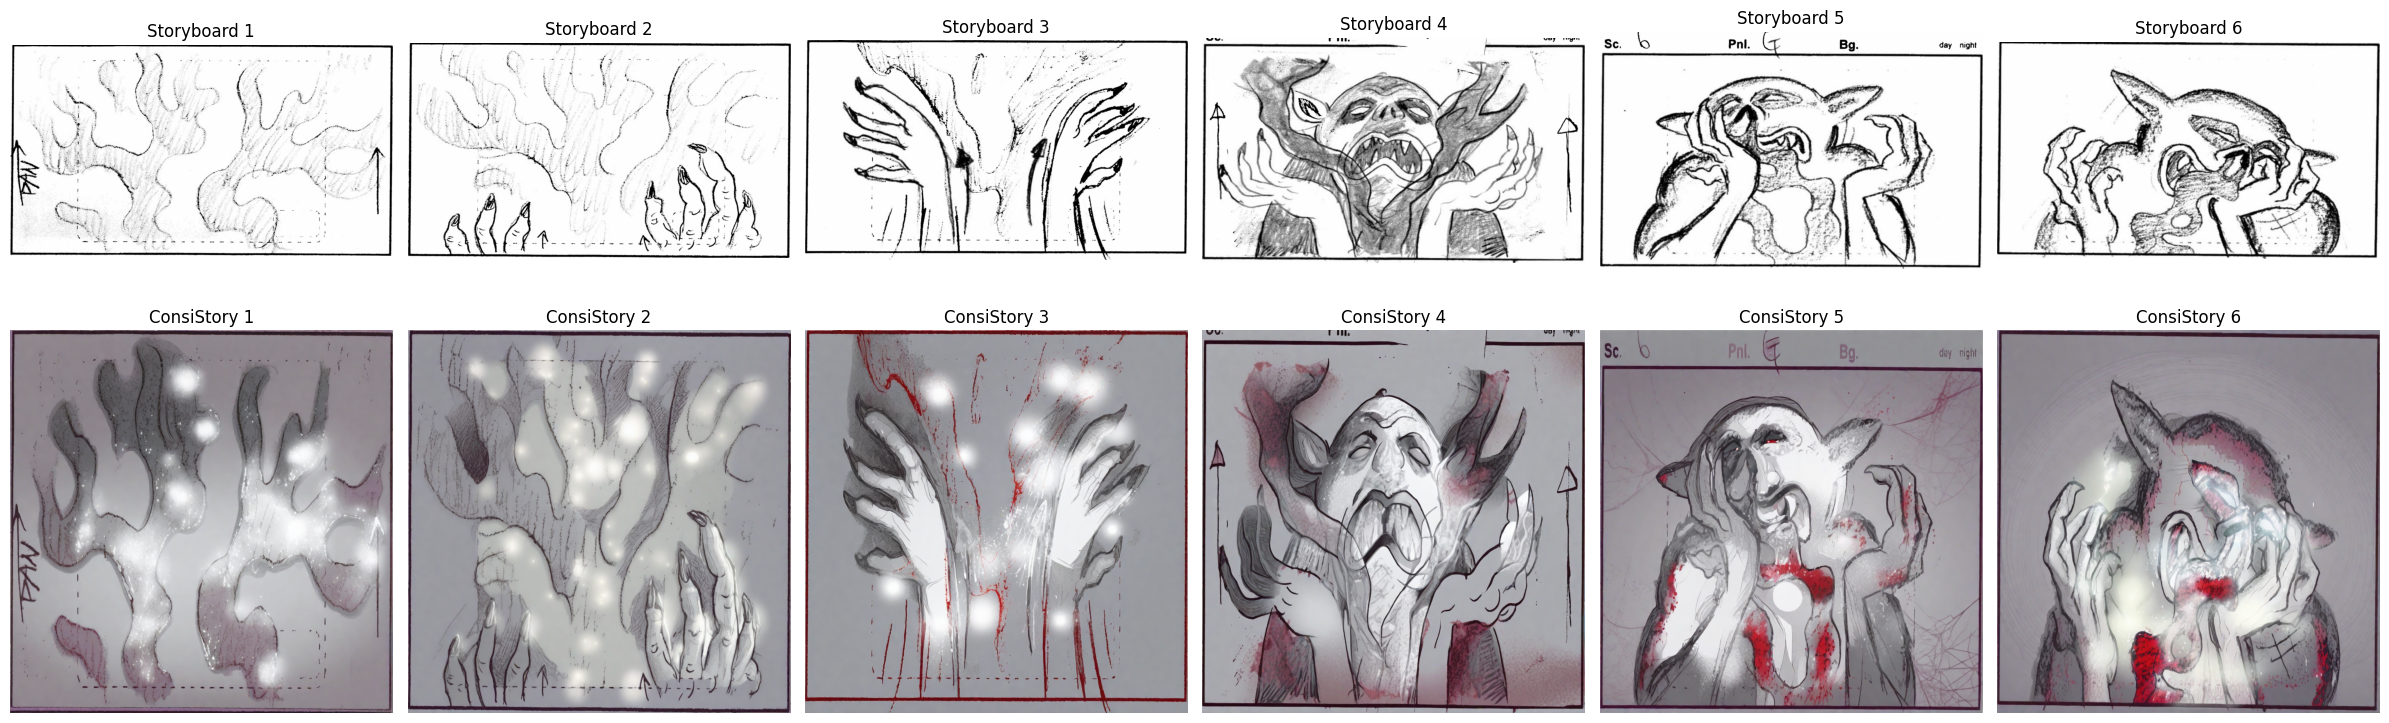

In [28]:
n = len(consistory_frames)

fig, axes = plt.subplots(
    2,
    n,
    figsize=(
        4 * n,
        8,
    ),
)

for i in range(n):

    axes[0, i].imshow(
        load_rgb(
            panel_files[i]
        )
    )

    axes[0, i].set_title(
        f"Storyboard {i + 1}"
    )

    axes[0, i].axis("off")


    axes[1, i].imshow(
        consistory_frames[i]
    )

    axes[1, i].set_title(
        f"ConsiStory {i + 1}"
    )

    axes[1, i].axis("off")


plt.tight_layout()
plt.show()

In [29]:
ddim_scheduler = story_pipeline.scheduler

ddim_anchor_cache_first_stage = (
    anchor_cache_first_stage
)

ddim_anchor_cache_second_stage = (
    anchor_cache_second_stage
)

# Existing successful Panel 4 result
ddim_panel4 = test_output.copy()

print("✓ Saved DDIM reference state")

✓ Saved DDIM reference state


## Switch to second-order DPM-Solver++

In [30]:
from diffusers import (
    DPMSolverMultistepScheduler,
)

DPM_STEPS = 20

story_pipeline.scheduler = (
    DPMSolverMultistepScheduler.from_config(
        ddim_scheduler.config,

        algorithm_type="dpmsolver++",

        # Recommended for guided generation
        solver_order=2,

        # Recommended second-order formulation
        solver_type="midpoint",

        # Do not use dynamic thresholding
        # with latent Stable Diffusion.
        thresholding=False,
    )
)

story_pipeline.scheduler.set_timesteps(
    DPM_STEPS
)

dpm_timesteps = [
    int(t)
    for t in story_pipeline.scheduler.timesteps
]

print("DPM-Solver++ timesteps:")
print(dpm_timesteps)

DPM-Solver++ timesteps:
[941, 894, 847, 800, 753, 706, 659, 612, 565, 518, 471, 424, 377, 330, 283, 236, 189, 142, 95, 48]


In [31]:
ORIGINAL_DIFT_TIMESTEP = 261

dpm_dift_timestep = min(
    dpm_timesteps,
    key=lambda t: abs(
        t - ORIGINAL_DIFT_TIMESTEP
    ),
)

print(
    "Original ConsiStory DIFT timestep:",
    ORIGINAL_DIFT_TIMESTEP,
)

print(
    "Nearest DPM-Solver++ timestep:",
    dpm_dift_timestep,
)

Original ConsiStory DIFT timestep: 261
Nearest DPM-Solver++ timestep: 283


In [32]:
from consistory_utils import (
    DIFTLatentStore,
)


class SchedulerAwareDIFTLatentStore(
    DIFTLatentStore
):
    """
    Capture DIFT features at the timestep actually
    used by the active scheduler.

    Also expose the captured feature under ConsiStory's
    original '261_0' key so the released code and our
    existing helpers continue to work unchanged.
    """

    def __init__(
        self,
        capture_timestep,
        up_ft_indices=[0],
    ):
        super().__init__(
            steps=[
                int(capture_timestep)
            ],
            up_ft_indices=up_ft_indices,
        )

        self.capture_timestep = int(
            capture_timestep
        )


    def __call__(
        self,
        features,
        t,
        layer_index,
    ):
        t_int = int(t)

        if (
            t_int == self.capture_timestep
            and
            layer_index
            in self.up_ft_indices
        ):
            # Native scheduler-specific key.
            self.dift_features[
                f"{t_int}_{layer_index}"
            ] = features

            # Compatibility alias expected by
            # the released ConsiStory code.
            self.dift_features[
                f"261_{layer_index}"
            ] = features

In [33]:
if hasattr(
    story_pipeline.unet,
    "base_unet",
):
    consistory_base_unet = (
        story_pipeline.unet.base_unet
    )
else:
    consistory_base_unet = (
        story_pipeline.unet
    )


consistory_base_unet.latent_store = (
    SchedulerAwareDIFTLatentStore(
        capture_timestep=(
            dpm_dift_timestep
        ),
        up_ft_indices=[0],
    )
)

print(
    "✓ DIFT capture configured for:",
    dpm_dift_timestep,
)

✓ DIFT capture configured for: 283


## Regenerate the anchors under DPM-Solver++

In [34]:
story_pipeline.unet.clear_control_image()

gc.collect()
torch.cuda.empty_cache()

In [35]:
import time

anchor_start = time.perf_counter()

(
    dpm_anchor_images,
    dpm_anchor_grid,
    dpm_anchor_cache_first_stage,
    dpm_anchor_cache_second_stage,
) = run_anchor_generation(
    story_pipeline=story_pipeline,

    prompts=ANCHOR_PROMPTS,

    concept_token=CONCEPT_TOKEN,

    seed=CONFIG["seed"],

    n_steps=DPM_STEPS,

    mask_dropout=(
        CONFIG["mask_dropout"]
    ),

    same_latent=(
        CONFIG["same_latent"]
    ),

    share_queries=(
        CONFIG["share_queries"]
    ),

    perform_sdsa=True,

    perform_injection=True,

    cache_cpu_offloading=True,
)

anchor_time = (
    time.perf_counter()
    - anchor_start
)

print(
    f"✓ DPM anchors generated in "
    f"{anchor_time:.1f} sec"
)

[(1, 20)]


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

✓ DPM anchors generated in 44.7 sec


## Verify DIFT was actually captured

In [36]:
print(
    "DIFT keys:",
    list(
        consistory_base_unet
        .latent_store
        .dift_features
        .keys()
    )
)

DIFT keys: ['283_0', '261_0']


## Generate the same Panel 4 with DPM-Solver++

In [37]:
test_control_tensor = (
    prepare_control_image(
        test_condition
    )
)

story_pipeline.unet.set_control_image(
    test_control_tensor
)

story_pipeline.unet.conditioning_scale = (
    CONFIG[
        "controlnet_conditioning_scale"
    ]
)

consistory_base_unet.latent_store.reset()

gc.collect()
torch.cuda.empty_cache()

In [38]:
panel_start = time.perf_counter()

dpm_test_images = (
    run_extra_generation_controlled(
        story_pipeline=story_pipeline,

        prompts=[
            test_prompt
        ],

        concept_token=CONCEPT_TOKEN,

        anchor_cache_first_stage=(
            dpm_anchor_cache_first_stage
        ),

        anchor_cache_second_stage=(
            dpm_anchor_cache_second_stage
        ),

        seed=CONFIG["seed"],

        n_steps=DPM_STEPS,

        mask_dropout=(
            CONFIG["mask_dropout"]
        ),

        same_latent=(
            CONFIG["same_latent"]
        ),

        share_queries=(
            CONFIG["share_queries"]
        ),

        perform_sdsa=True,

        perform_injection=True,

        cache_cpu_offloading=True,

        guidance_scale=(
            CONFIG["guidance_scale"]
        ),

        negative_prompt=(
            CONFIG["negative_prompt"]
        ),
    )
)

dpm_panel_time = (
    time.perf_counter()
    - panel_start
)

dpm_panel4 = dpm_test_images[0]

print(
    f"✓ DPM-Solver++ Panel 4: "
    f"{dpm_panel_time:.1f} sec"
)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

✓ DPM-Solver++ Panel 4: 33.5 sec


## Compare DDIM vs DPM-Solver++ visually

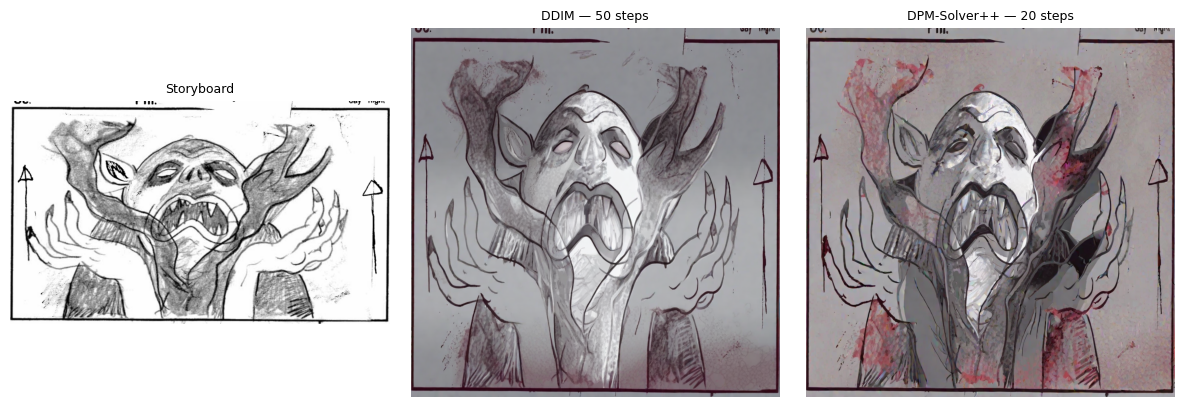

In [39]:
show(
    [
        test_storyboard,
        ddim_panel4,
        dpm_panel4,
    ],

    titles=[
        "Storyboard",
        "DDIM — 50 steps",
        "DPM-Solver++ — 20 steps",
    ],

    cols=3,
)

### Record the speedup

In [40]:
DDIM_ESTIMATED_PANEL_TIME = 68.0

speedup = (
    DDIM_ESTIMATED_PANEL_TIME
    / dpm_panel_time
)

print(
    f"Approx speedup: "
    f"{speedup:.2f}x"
)

Approx speedup: 2.03x


### Testing DMP++ a few more times

In [41]:
PILOT_PANEL_INDICES = [0, 3, 5]   # Panels 1, 4, 6
PILOT_LABELS = {
    0: "Panel 1",
    3: "Panel 4",
    5: "Panel 6",
}

print("Pilot panels:")
for idx in PILOT_PANEL_INDICES:
    print(
        f"- {PILOT_LABELS[idx]} | "
        f"{os.path.basename(panel_files[idx])} | "
        f"{prompts[idx]}"
    )

Pilot panels:
- Panel 1 | seq01_panel001.png | a vampire, jelly vaporizes as camera pans up, blank background
- Panel 4 | seq01_panel004.png | a vampire, camera pans upto vampire's face, close-up, blank background
- Panel 6 | seq01_panel006.png | a vampire, vampire inhales jelly mist from left hand, close-up, blank background


In [42]:
def run_single_panel_dpm_pilot(
    panel_index,
    story_pipeline,
    panel_files,
    prompts,
    anchor_cache_first_stage,
    anchor_cache_second_stage,
    cfg=CONFIG,
):
    panel_file = panel_files[panel_index]
    storyboard = load_rgb(panel_file)

    cond = make_condition(
        storyboard,
        mode=cfg["cond_mode"],
        size=cfg["resolution"],
        low=cfg["canny_low"],
        high=cfg["canny_high"],
    )

    control_tensor = prepare_control_image(cond)

    full_prompt = f"{prompts[panel_index]}, {cfg['prompt_suffix']}"

    story_pipeline.unet.set_control_image(control_tensor)
    story_pipeline.unet.conditioning_scale = cfg["controlnet_conditioning_scale"]

    # Reset only target-panel latent store state
    if hasattr(story_pipeline.unet, "base_unet"):
        story_pipeline.unet.base_unet.latent_store.reset()
    else:
        story_pipeline.unet.latent_store.reset()

    gc.collect()
    torch.cuda.empty_cache()

    start = time.perf_counter()

    try:
        images = run_extra_generation_controlled(
            story_pipeline=story_pipeline,
            prompts=[full_prompt],
            concept_token=CONCEPT_TOKEN,
            anchor_cache_first_stage=anchor_cache_first_stage,
            anchor_cache_second_stage=anchor_cache_second_stage,
            seed=cfg["seed"],
            n_steps=DPM_STEPS,
            mask_dropout=cfg["mask_dropout"],
            same_latent=cfg["same_latent"],
            share_queries=cfg["share_queries"],
            perform_sdsa=True,
            perform_injection=True,
            cache_cpu_offloading=True,
            guidance_scale=cfg["guidance_scale"],
            negative_prompt=cfg["negative_prompt"],
        )

        elapsed = time.perf_counter() - start
        output = images[0]

    finally:
        story_pipeline.unet.clear_control_image()
        del control_tensor
        gc.collect()
        torch.cuda.empty_cache()

    return {
        "panel_index": panel_index,
        "panel_name": f"Panel {panel_index + 1}",
        "panel_file": panel_file,
        "prompt": prompts[panel_index],
        "storyboard": storyboard,
        "condition": cond,
        "output": output,
        "time_sec": elapsed,
    }

In [43]:
dpm_pilot_results = []

for idx in PILOT_PANEL_INDICES:
    print("\n" + "=" * 60)
    print(f"Running DPM++ pilot for Panel {idx + 1}")
    print("=" * 60)

    result = run_single_panel_dpm_pilot(
        panel_index=idx,
        story_pipeline=story_pipeline,
        panel_files=panel_files,
        prompts=prompts,
        anchor_cache_first_stage=dpm_anchor_cache_first_stage,
        anchor_cache_second_stage=dpm_anchor_cache_second_stage,
        cfg=CONFIG,
    )

    dpm_pilot_results.append(result)

    print(
        f"✓ Completed {result['panel_name']} "
        f"in {result['time_sec']:.1f} sec"
    )


Running DPM++ pilot for Panel 1


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

✓ Completed Panel 1 in 33.8 sec

Running DPM++ pilot for Panel 4


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

✓ Completed Panel 4 in 33.7 sec

Running DPM++ pilot for Panel 6


  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/20 [00:00<?, ?it/s]

✓ Completed Panel 6 in 33.3 sec


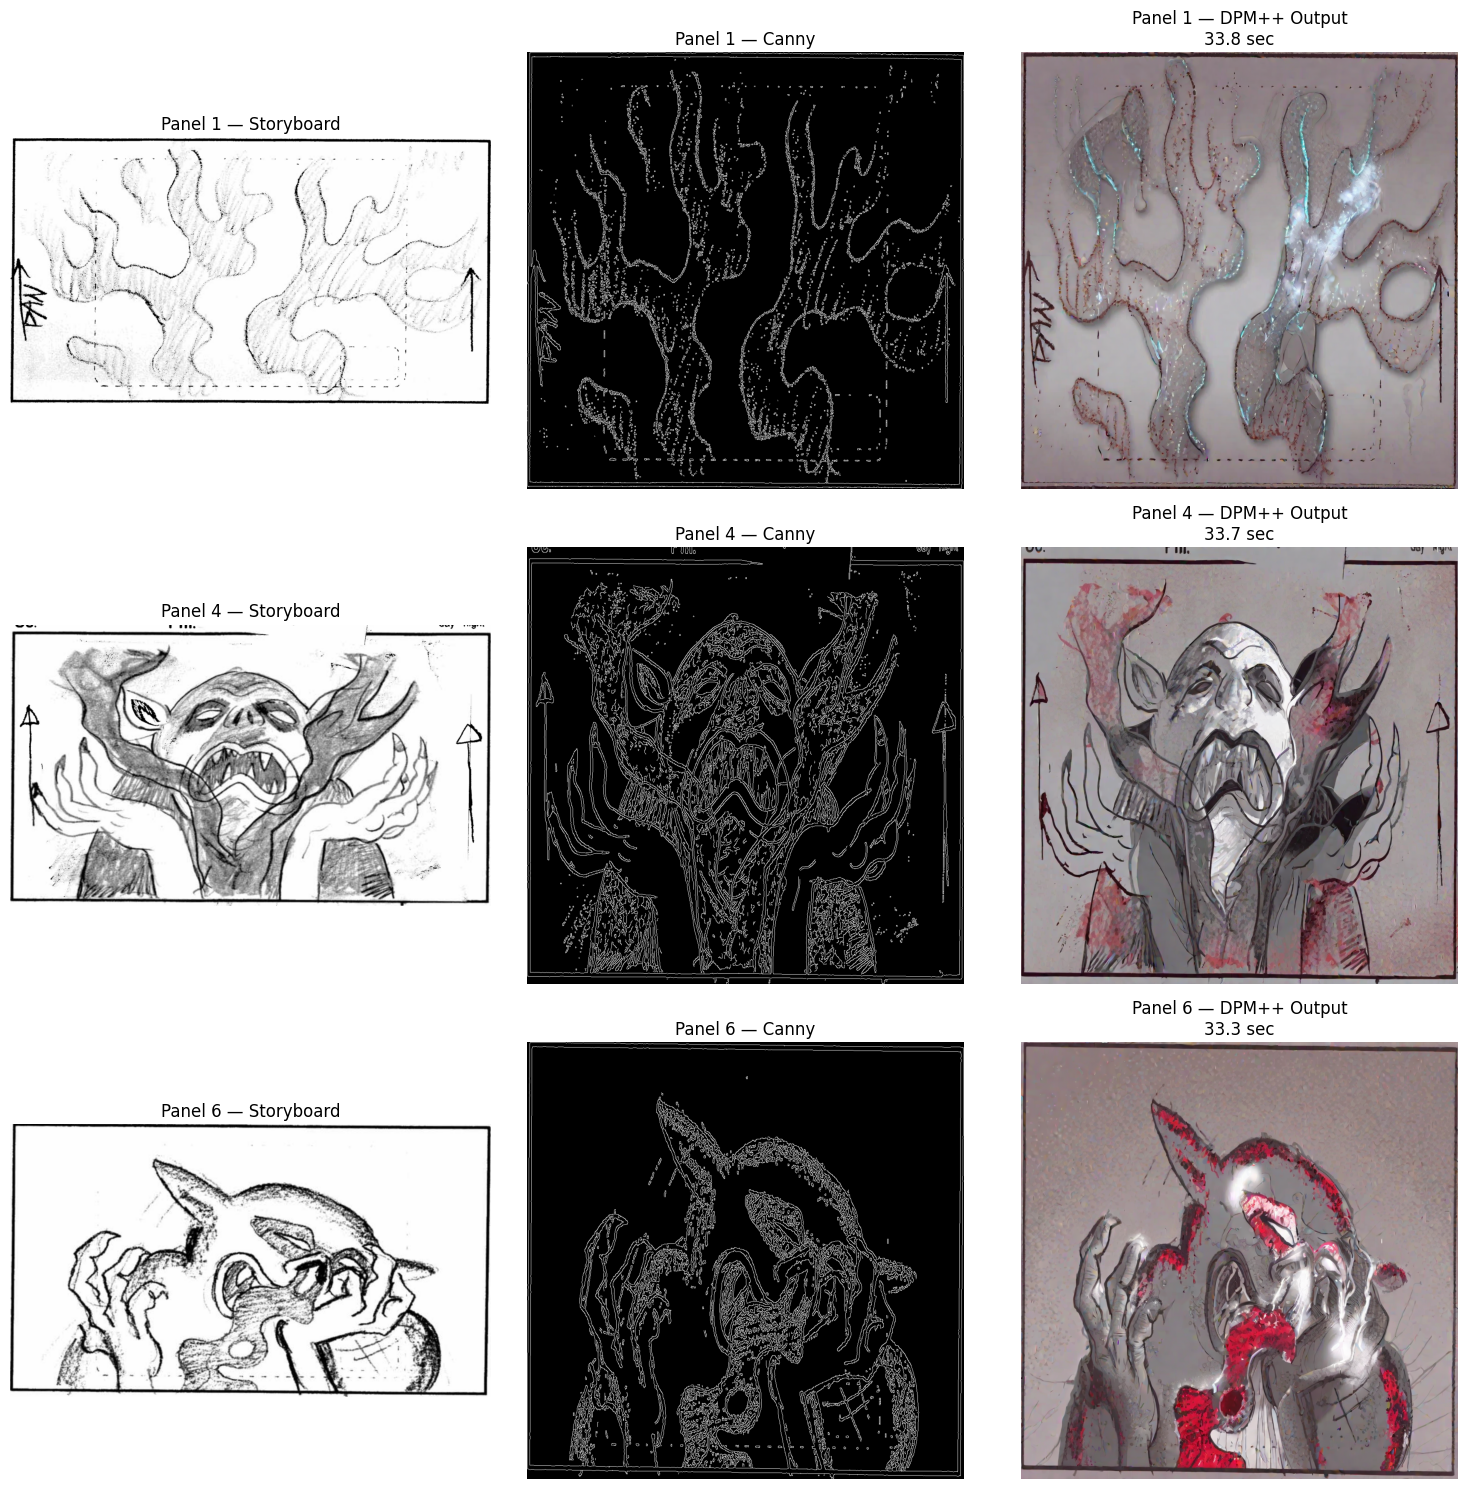

In [44]:
fig, axes = plt.subplots(
    len(dpm_pilot_results),
    3,
    figsize=(15, 5 * len(dpm_pilot_results)),
)

if len(dpm_pilot_results) == 1:
    axes = np.array([axes])

for row, result in enumerate(dpm_pilot_results):
    axes[row, 0].imshow(result["storyboard"])
    axes[row, 0].set_title(f"{result['panel_name']} — Storyboard")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(result["condition"])
    axes[row, 1].set_title(f"{result['panel_name']} — Canny")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(result["output"])
    axes[row, 2].set_title(
        f"{result['panel_name']} — DPM++ Output\n"
        f"{result['time_sec']:.1f} sec"
    )
    axes[row, 2].axis("off")

plt.tight_layout()
plt.show()

In [45]:
print("DPM-Solver++ Pilot Summary")
print("-" * 40)

total_time = 0.0

for result in dpm_pilot_results:
    total_time += result["time_sec"]
    print(
        f"{result['panel_name']}: "
        f"{result['time_sec']:.1f} sec"
    )

avg_time = total_time / len(dpm_pilot_results)

print("-" * 40)
print(f"Average time: {avg_time:.1f} sec")
print(f"Total time:   {total_time:.1f} sec")

DPM-Solver++ Pilot Summary
----------------------------------------
Panel 1: 33.8 sec
Panel 4: 33.7 sec
Panel 6: 33.3 sec
----------------------------------------
Average time: 33.6 sec
Total time:   100.8 sec


In [46]:
PILOT_OUT_DIR = os.path.join(
    OUTPUT_DIR,
    "controlnet_consistory_dpmpp_pilot",
    seq_name,
)

os.makedirs(PILOT_OUT_DIR, exist_ok=True)

for result in dpm_pilot_results:
    panel_num = result["panel_index"] + 1

    result["output"].save(
        os.path.join(
            PILOT_OUT_DIR,
            f"panel{panel_num:02d}_dpmpp.png",
        )
    )

    result["condition"].save(
        os.path.join(
            PILOT_OUT_DIR,
            f"panel{panel_num:02d}_cond.png",
        )
    )

print("Saved pilot outputs to:")
print(PILOT_OUT_DIR)

Saved pilot outputs to:
/content/drive/MyDrive/cmpe261_project/outputs/controlnet_consistory_dpmpp_pilot/seq01
